# Topological Photonic Crystals II — Domain Walls Excited by Circularly Polarized Sources

The edge states of notebook 01 carry a pseudospin (spin-Hall) or a valley index
(valley-Hall) that is locked to their propagation direction along the wall. A source that
emits only one handedness should therefore launch light in one direction only. This
notebook drives each of the four walls with a circularly polarized dipole and measures
how the emitted power splits between the two directions along the wall.

| wall | sample | source | drive |
|---|---|---|---|
| spin-Hall pillars (TM) | 20 clusters × (15 topological + 15 trivial) rows | Hx ± iHy on the wall, midway between two topological clusters (air) | 0.457 c/a0 |
| spin-Hall holes (TE) | 20 clusters × (20 + 20) rows | Ex ± iEy in the topological cluster next to the wall, 0.06 a0 above its centre (Si) | 0.405 c/a0 |
| valley-Hall holes (TE) | 35 cells × (17 VPC1 + 17 VPC2) rows, bearded | Ex ± iEy near the centre of a small VPC2 hole, second row below the wall (air) | 0.2368 c/a |
| valley-Hall pillars (TM) | 35 cells × (17 + 17) rows, bearded | Hx ± iHy near the centre of a small VPC1 rod, second row above the wall (Si) | 0.265 c/a |

Each sample is long enough along the wall, and has enough rows across it, that η changes by
less than 0.01 and less than 1 % of the power reaches the PML through the bulk crystals when
either is increased (a0 = √3 a). Each drive frequency lies
on the edge band inside the shared bulk gap (notebook 01); for the spin-Hall walls it is
on the lower branch, clear of the small anticrossing at kx = 0. S+ (S−) rotates
counterclockwise (clockwise) seen from +z (Meep's exp(−iωt) convention).

**Where the source goes.** By reciprocity a point dipole d at r0 couples to a guided mode
with amplitude ∝ F*(r0)·d, where F is the mode's in-plane E (TE) or H (TM), and the
counter-propagating mode is F* (time reversal). A circular dipole therefore splits its
guided power with directionality C = 2 Im(Fx* Fy)/(|Fx|² + |Fy|²), the local degree of
circular polarization of the edge mode, and couples in proportion to S0 = |Fx|² + |Fy|²
(Lodahl et al. 2017; Söllner et al. 2015). Section 2 maps both over the wall. A good source
point needs |C| ≈ 1 *and* strong coupling: power that does not enter the edge mode radiates
into the bulk crystals, and the part of it that crosses the side planes goes both ways.
Each source sits on a vertical mirror line of the wall, so the mirror check of Section 4
applies. Valley-Hall: the |C| ≥ 0.98 point of largest S0 on a mirror line. Spin-Hall: the most
directional of the high-|C| points on the mirror lines, compared in FDTD
(`scripts/scan_spin_sources.py`); for the holes this is 0.06 a0 above the cluster centre,
where C = 0.996. A twofold-rotation centre of the wall cannot host a
directional source: a 180° rotation maps the wall onto itself, reverses the propagation
direction and leaves the handedness of the dipole unchanged, so C = 0 there (Section 5).

**Model:** edge-mode chirality from an MPB ribbon; 2D Meep, CW source with a smooth
turn-on, εd = 11.7 / air; resolution 32/a0 (spin-Hall pillars), 64/a0 (spin-Hall holes) and 24/a (valley-Hall),
each checked against a finer grid (`scripts/scan_spin_rows.py` for the spin-Hall walls). The
spin-Hall hole wall is driven only 0.004 c/a0 above the lower edge of its bulk gap, and its
triangular holes have sharp corners; at 32/a0 it gives η = 0.83, at 48/a0 0.980, at 64/a0 0.990. the lattice continues through the PML along the wall,
and the rows are followed by background material and PML across it. Complex fields give
the time-averaged Poynting vector directly.

**Kernel:** `mp` conda env, run from `topological/notebooks/`. **Do not use "Run All."**

## 0. Setup

In [1]:
# Imports, style, the four runs.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle, Polygon

from pic_toolkit import style
from pic_toolkit.meep_sim import topological_pc as tp

style.apply_style()
DATA = Path.cwd().parent / "data" / "walls"
RUNS = {"spin_tm": 0.457, "spin_te": 0.405, "valley_te": 0.2368, "valley_tm": 0.265}
TITLE = {"spin_tm": "spin-Hall pillars (TM)", "spin_te": "spin-Hall holes (TE)",
         "valley_te": "valley-Hall holes (TE)", "valley_tm": "valley-Hall pillars (TM)"}
UNIT = {"spin_tm": "a0", "spin_te": "a0", "valley_te": "a", "valley_tm": "a"}

def load(kind, spin, source_at="default"):
    tag = "" if source_at == "default" else f"_{source_at}"
    return dict(np.load(DATA / f"{kind}_f{RUNS[kind]:.4f}_s{'p' if spin > 0 else 'm'}{tag}.npz"))

## 1. The walls and source positions

Zoom around each source: inclusions (rods or holes), the wall (dashed) and the source (★), positions from `tp.source_position`.
Spin-Hall: topological crystal below the wall, trivial above. Valley-Hall: VPC1 above,
VPC2 below, the large inclusions facing each other across the wall.

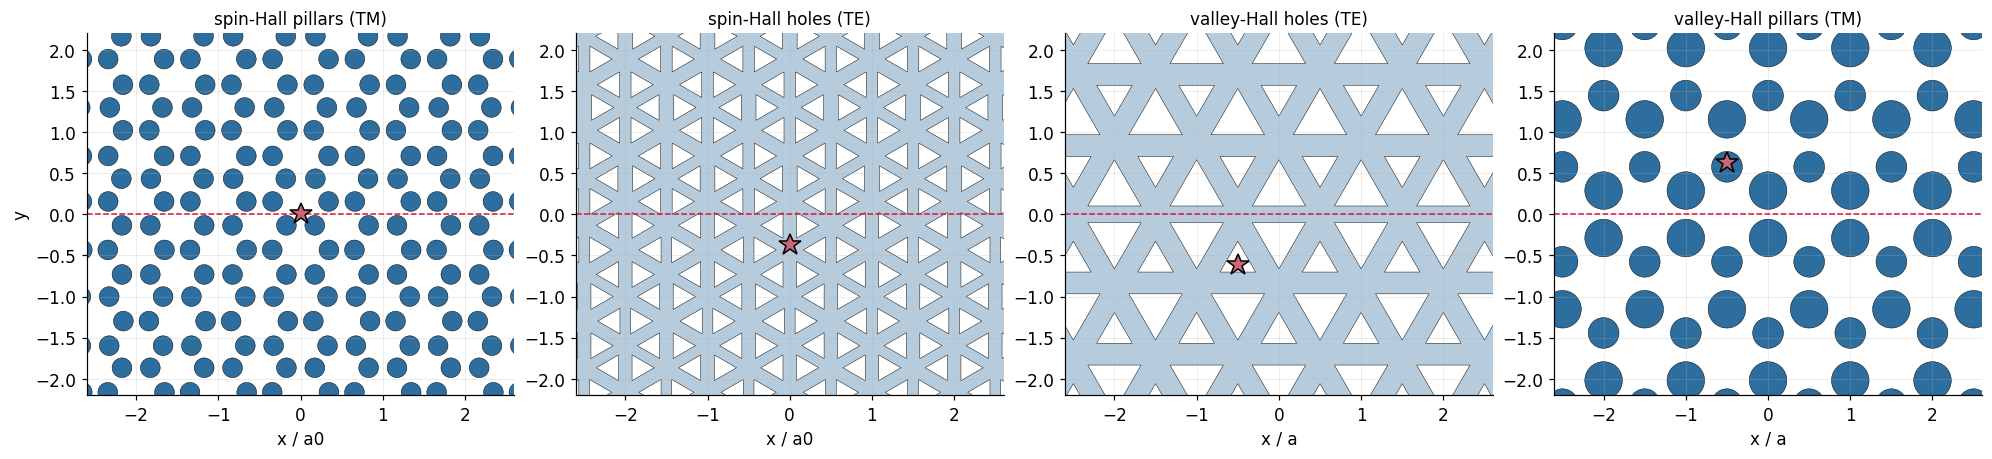

In [2]:
# Draw the inclusions near each source from the same generator the simulations use.
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), layout="constrained")
for ax, kind in zip(axes, tp.KINDS):
    (xs, ys), x_shift = tp.source_position(kind)
    bg = style.COLOR_STEEL if kind.endswith("_te") else "white"
    ax.add_patch(plt.Rectangle((-4, -4), 8, 8, color=bg, alpha=0.35 if bg != "white" else 1))
    for sh in tp.wall_shapes(kind, -4, 4, 4, x_shift):
        fc = "white" if kind.endswith("_te") else style.COLOR_STEEL
        if "circle" in sh:
            ax.add_patch(Circle(sh["circle"], sh["r"], fc=fc, ec="k", lw=0.3))
        else:
            ax.add_patch(Polygon(sh["poly"], fc=fc, ec="k", lw=0.3))
    ax.axhline(0, color=style.COLOR_ANNOTATION, ls="--", lw=1)
    ax.plot(xs, ys, marker="*", color=style.COLOR_ROSE, ms=15, mec="k")
    ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.2, 2.2); ax.set_aspect("equal")
    ax.set_title(TITLE[kind], fontsize=11); ax.set_xlabel(f"x / {UNIT[kind]}")
axes[0].set_ylabel("y")
fig.savefig(DATA.parent / "fig_wall_geometry.png", dpi=150, bbox_inches="tight")
plt.show()

> **STOP -- the four ribbon solves take ≈ 4 min in total** (`scripts/chirality_maps.py`,
> cached in `data/walls/chirality_maps.npz`). The cell below only reads the cache.

## 2. Edge-mode chirality: where a circular dipole couples one way

The edge mode at the drive frequency, solved on a periodic ribbon (8 + 8 rows, same
resolution and lattice position as the FDTD sample). The ribbon wraps round and so has a
second wall; for the spin-Hall walls the nearly degenerate modes of the two walls are
recombined into the one on y = 0. Top: C, the directionality an S+ source at that point
gives (positive: to the left, Section 4's sign). Bottom: S0, its coupling strength,
normalized to the maximum within 1.5 rows of the wall (for the TE walls that maximum sits at
the sharp hole corners). |C| ≈ 1 is common, at cluster and inclusion centres among other
places, but often where S0 is small; C changes sign over a fraction of a lattice constant,
so the handedness that goes left depends on the source point, not only on the wall.

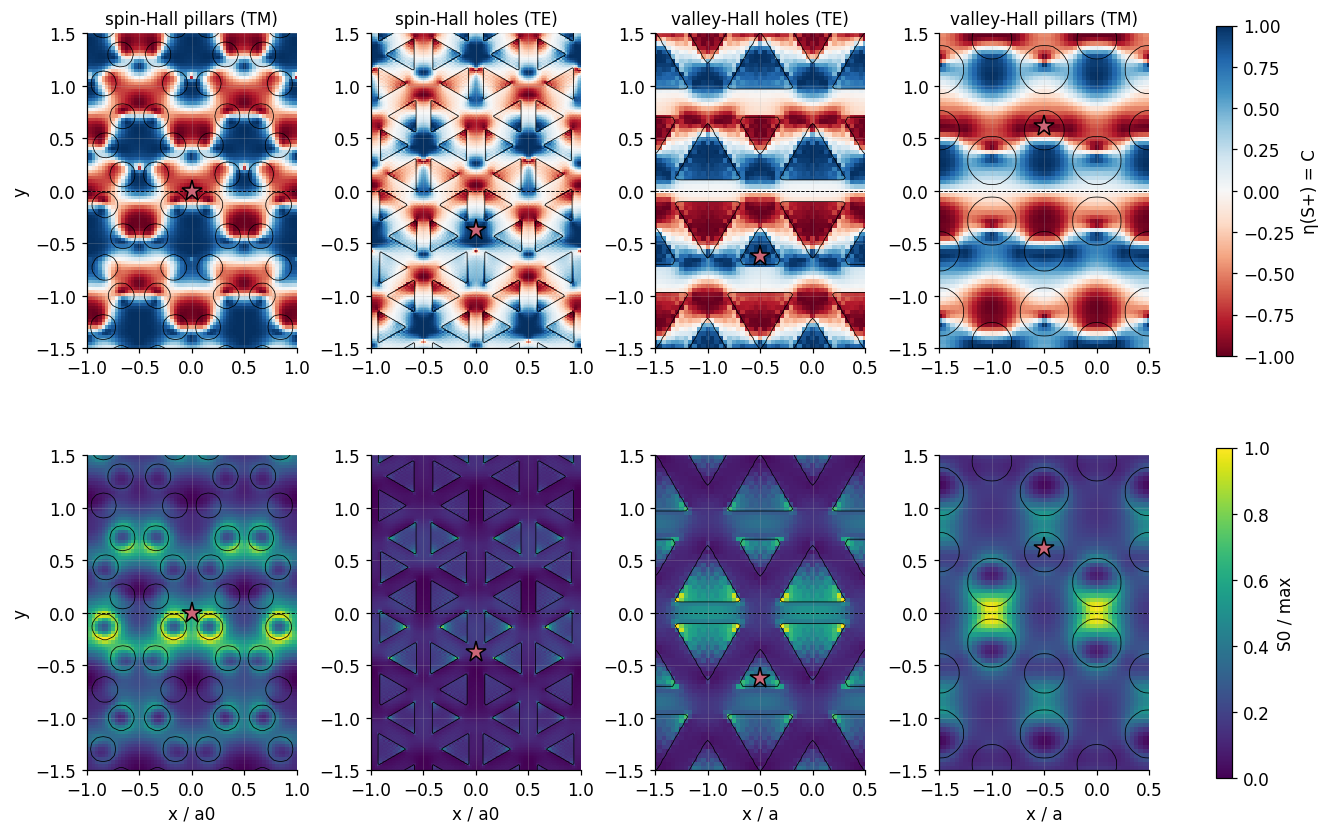

                      wall      kx     source (x, y)  medium       C  S0/max
    spin-Hall pillars (TM)  0.0294 (+0.000, +0.000)     air  -0.988    0.57
      spin-Hall holes (TE)  0.0218 (+0.000, -0.371)      Si  +0.996    0.13
    valley-Hall holes (TE)  0.3180 (-0.500, -0.619)     air  +0.999    0.43
  valley-Hall pillars (TM)  0.3431 (-0.500, +0.619)      Si  -0.995    0.30


In [3]:
# Predicted directionality eta(S+) = C (top) and coupling strength S0 (bottom) of each wall's
# edge mode, tiled over three periods along the wall; star: the source position used below.
CH = np.load(DATA / "chirality_maps.npz")
fig, axes = plt.subplots(2, 4, figsize=(12, 7.8), layout="constrained")
for c, kind in enumerate(tp.KINDS):
    x, y, eps = CH[f"{kind}_x"], CH[f"{kind}_y"], CH[f"{kind}_eps"]
    C, s0 = CH[f"{kind}_C_left"], CH[f"{kind}_s0"]
    near = np.abs(y) <= 1.5 * tp.ROW_H
    xt = np.concatenate([x - 1, x, x + 1])
    tile = lambda a: np.concatenate([a, a, a], axis=0)
    (xs, ys), _ = tp.source_position(kind)
    for r, (data, kw, lab) in enumerate((
            (C, dict(cmap=style.CMAP_FIELD, vmin=-1, vmax=1), "η(S+) = C"),
            (s0 / s0[:, near].max(), dict(cmap=style.CMAP_DENSITY, vmin=0, vmax=1), "S0 / max"))):
        ax = axes[r, c]
        im = ax.pcolormesh(xt, y, tile(data).T, shading="auto", rasterized=True, **kw)
        ax.contour(xt, y, tile(eps).T, levels=[6], colors="k", linewidths=0.5)
        ax.axhline(0, color="k", lw=0.6, ls="--")
        ax.plot(xs, ys, "*", color=style.COLOR_ROSE, ms=14, mec="k")
        ax.set_xlim(xs - 1, xs + 1); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal")
        if r == 0:
            ax.set_title(TITLE[kind], fontsize=11)
        else:
            ax.set_xlabel(f"x / {UNIT[kind]}")
        if c == 3:
            fig.colorbar(im, ax=axes[r, :], shrink=0.8, label=lab)
for ax in axes[:, 0]:
    ax.set_ylabel("y")
fig.savefig(DATA.parent / "fig_wall_chirality.png", dpi=150, bbox_inches="tight")
plt.show()

# Edge mode and chirality at the source of each wall (nearest ribbon grid point).
print(f"{'wall':>26} {'kx':>7} {'source (x, y)':>17} {'medium':>7} {'C':>7} {'S0/max':>7}")
for kind in tp.KINDS:
    x, y, s0 = CH[f"{kind}_x"], CH[f"{kind}_y"], CH[f"{kind}_s0"]
    (xs, ys), _ = tp.source_position(kind)
    i, j = np.argmin(np.abs(x - ((xs + 0.5) % 1 - 0.5))), np.argmin(np.abs(y - ys))
    med = "Si" if CH[f"{kind}_eps"][i, j] > 6 else "air"
    print(f"{TITLE[kind]:>26} {float(CH[f'{kind}_kx']):>7.4f} ({xs:+.3f}, {ys:+.3f}) {med:>7} "
          f"{CH[f'{kind}_C_left'][i, j]:>+7.3f} {s0[i, j] / s0[:, np.abs(y) <= 1.5 * tp.ROW_H].max():>7.2f}")


> **STOP -- the eight runs (4 walls × S±) take 3–8 min each on 12 cores, ≈ 55 min for the spin-Hall holes** (`scripts/run_walls.py`,
> cached in `data/walls/`). The cells below only read the cache.

## 3. Field distributions

For each wall and each handedness: the signed field that carries the polarization's
scalar component (Re Hz for TE, Re Ez for TM; red/blue) and the electric energy density
|E|² (|Ex|² + |Ey|² for TE, |Ez|² for TM; log scale). Both are normalized to their maximum
more than 1.5 lattice constants from the source, so the guided wave rather than the
source's near field sets the scale. Field maps are stored at every second grid point.

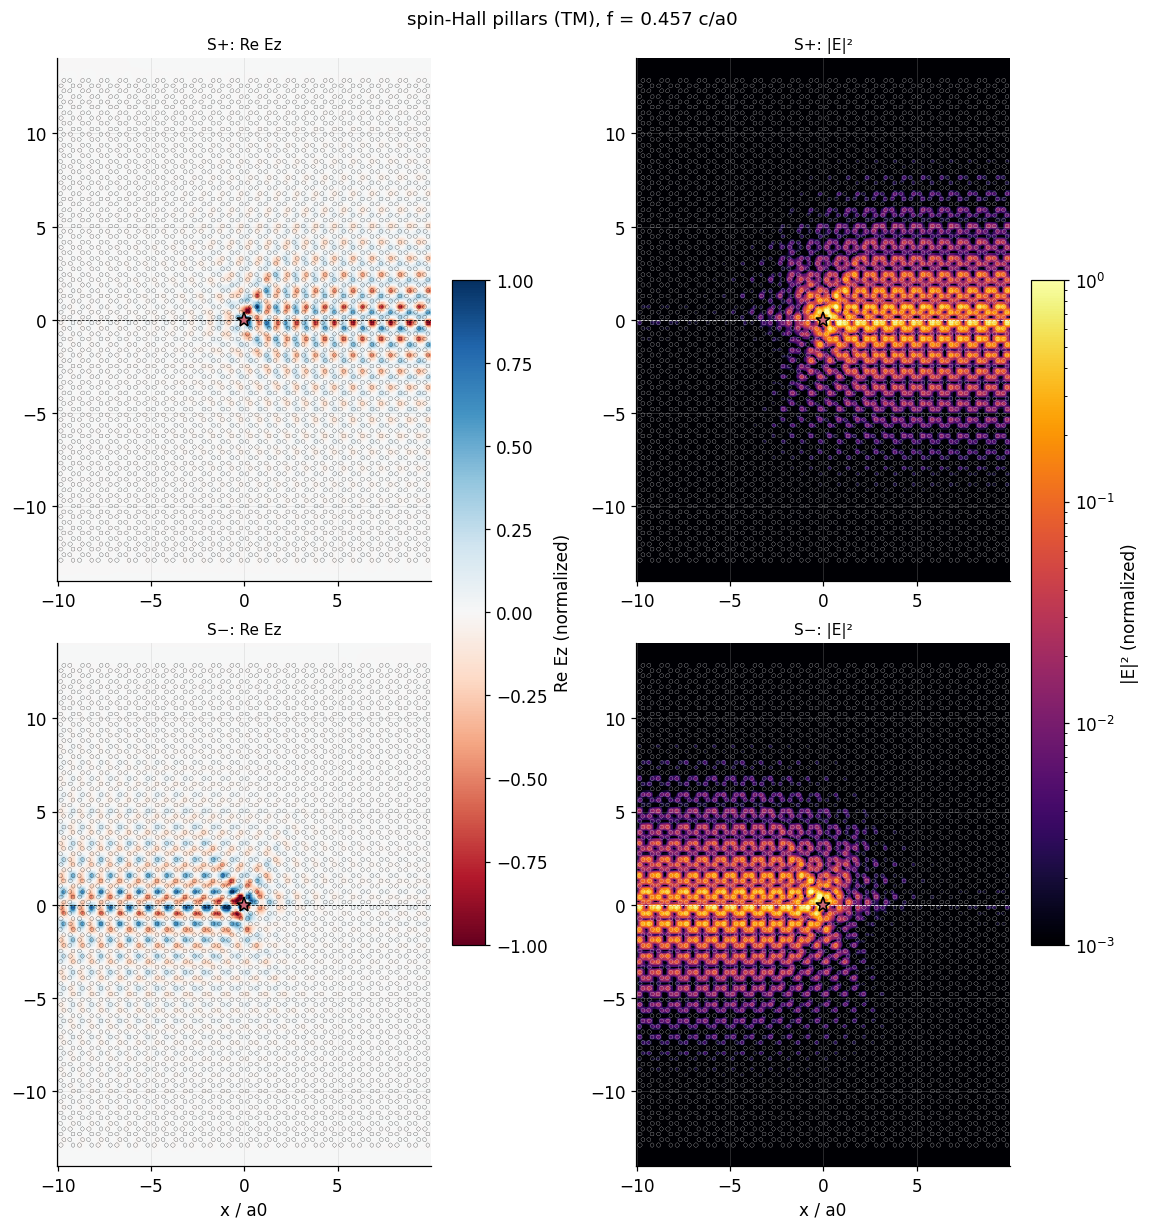

In [4]:
# One 2 x 2 figure per wall: rows S+ / S-, columns signed field / |E|^2.
def field_figure(kind):
    pol = tp.POLARIZATION[kind]
    comp = "hz" if pol == "TE" else "ez"
    # Figure size follows the sample's aspect ratio (the spin-Hall samples are taller than wide).
    o = load(kind, +1)
    aspect = 2 * (o["n_rows"] * tp.ROW_H + o["pad_y"]) / o["n_x"]
    w = 5.6 if aspect < 1 else 3.6
    fig, axes = plt.subplots(2, 2, figsize=(2 * w + 3.2, 2 * w * aspect + 1.0), layout="constrained")
    for r, s in enumerate((+1, -1)):
        o = load(kind, s)
        x, y = o["x"], o["y"]
        ix = np.abs(x) <= o["n_x"] / 2
        iy = np.abs(y) <= o["n_rows"] * tp.ROW_H + o["pad_y"]
        X, Y = np.meshgrid(x[ix], y[iy], indexing="ij")
        far = np.hypot(X - o["src_xy"][0], Y - o["src_xy"][1]) > 1.5
        F = o[comp][np.ix_(ix, iy)]
        F = (F * np.exp(-1j * np.angle(F.flat[np.abs(F).argmax()]))).real
        E2 = o["E2"][np.ix_(ix, iy)]
        eps = o["eps"][np.ix_(ix, iy)]
        for c, (data, kw, lab) in enumerate((
                (F / np.abs(F[far]).max(), dict(cmap=style.CMAP_FIELD, vmin=-1, vmax=1), f"Re {comp[0].upper()}{comp[1]}"),
                (E2 / E2[far].max(), dict(cmap="inferno", norm=LogNorm(1e-3, 1)), "|E|²"))):
            ax = axes[r, c]
            im = ax.pcolormesh(x[ix], y[iy], data.T, shading="auto", rasterized=True, **kw)
            ax.contour(x[ix], y[iy], eps.T, levels=[6], colors="k" if c == 0 else "w", linewidths=0.15)
            ax.axhline(0, color="k" if c == 0 else "w", lw=0.5, ls="--")
            ax.plot(*o["src_xy"], "*", color=style.COLOR_ROSE, ms=10, mec="k")
            ax.set_aspect("equal")
            ax.set_title(f"{'S+' if s > 0 else 'S−'}: {lab}", fontsize=10)
            if r == 1:
                ax.set_xlabel(f"x / {UNIT[kind]}")
            if r == 0:
                fig.colorbar(im, ax=axes[:, c], shrink=0.6, label=lab + " (normalized)")
    fig.suptitle(f"{TITLE[kind]}, f = {RUNS[kind]} c/{UNIT[kind]}", fontsize=12)
    fig.savefig(DATA.parent / f"fig_wall_fields_{kind}.png", dpi=130, bbox_inches="tight")
    plt.show()

field_figure("spin_tm")

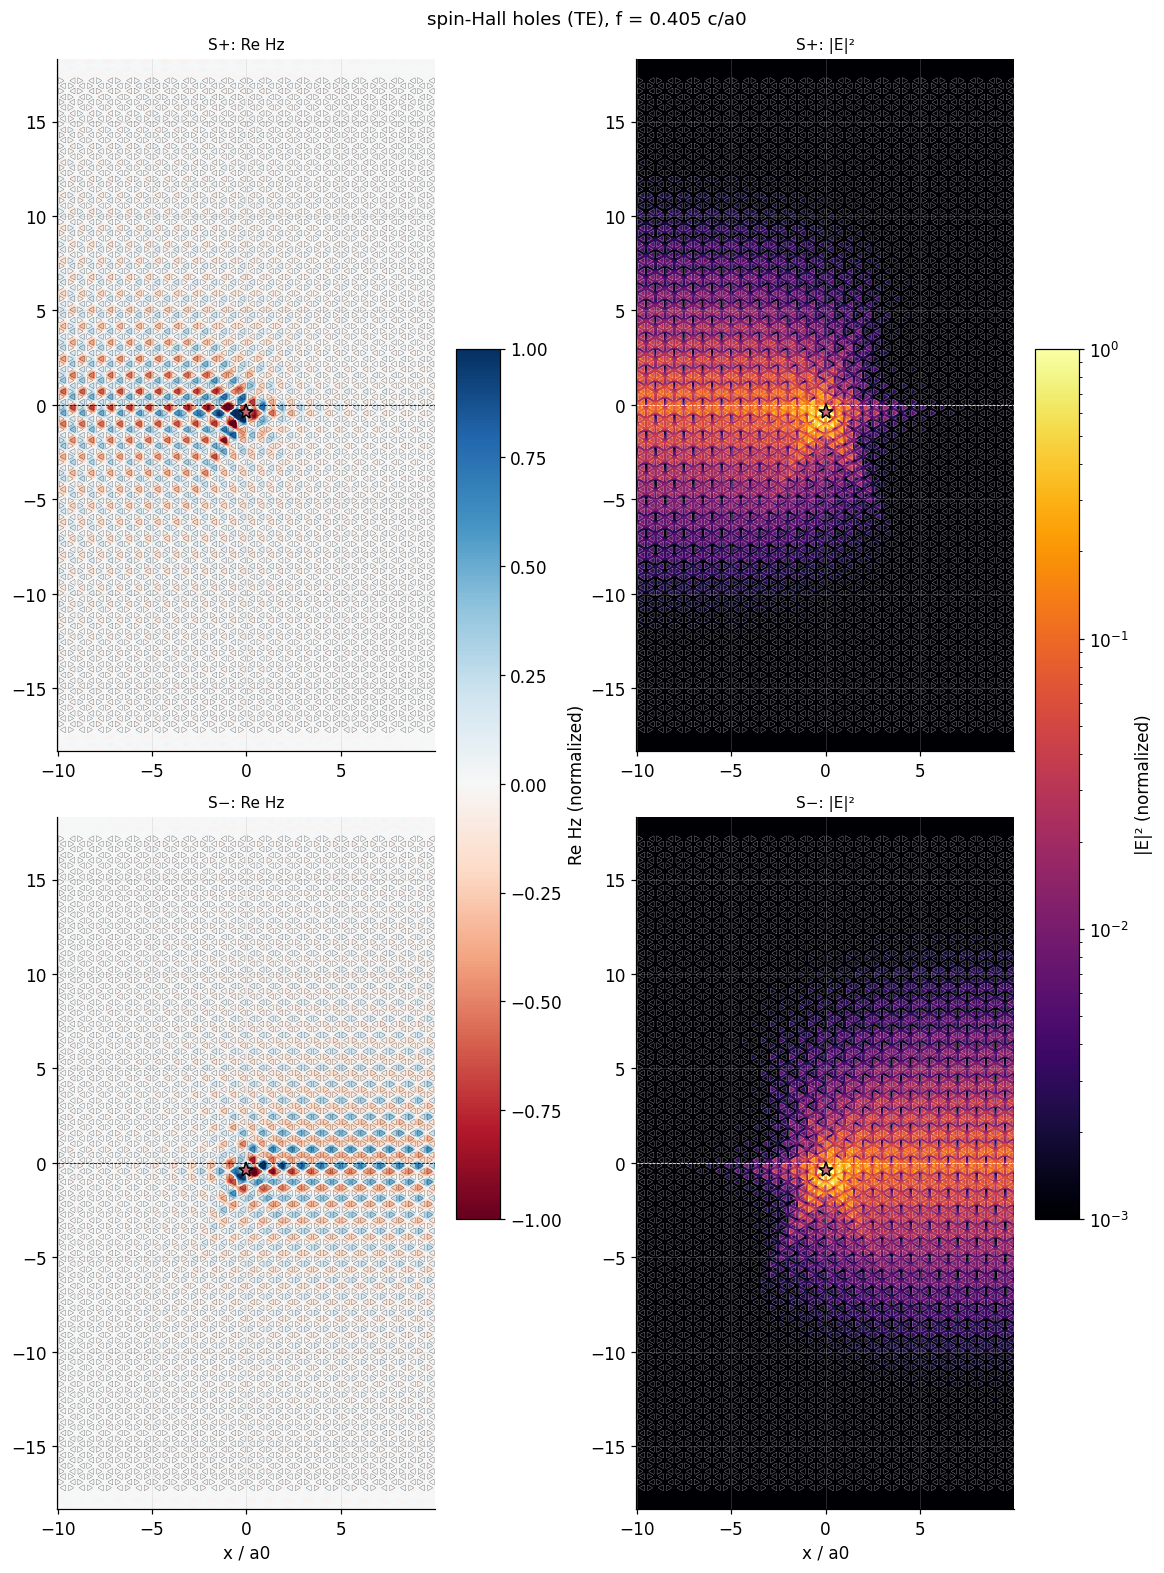

In [5]:
field_figure("spin_te")

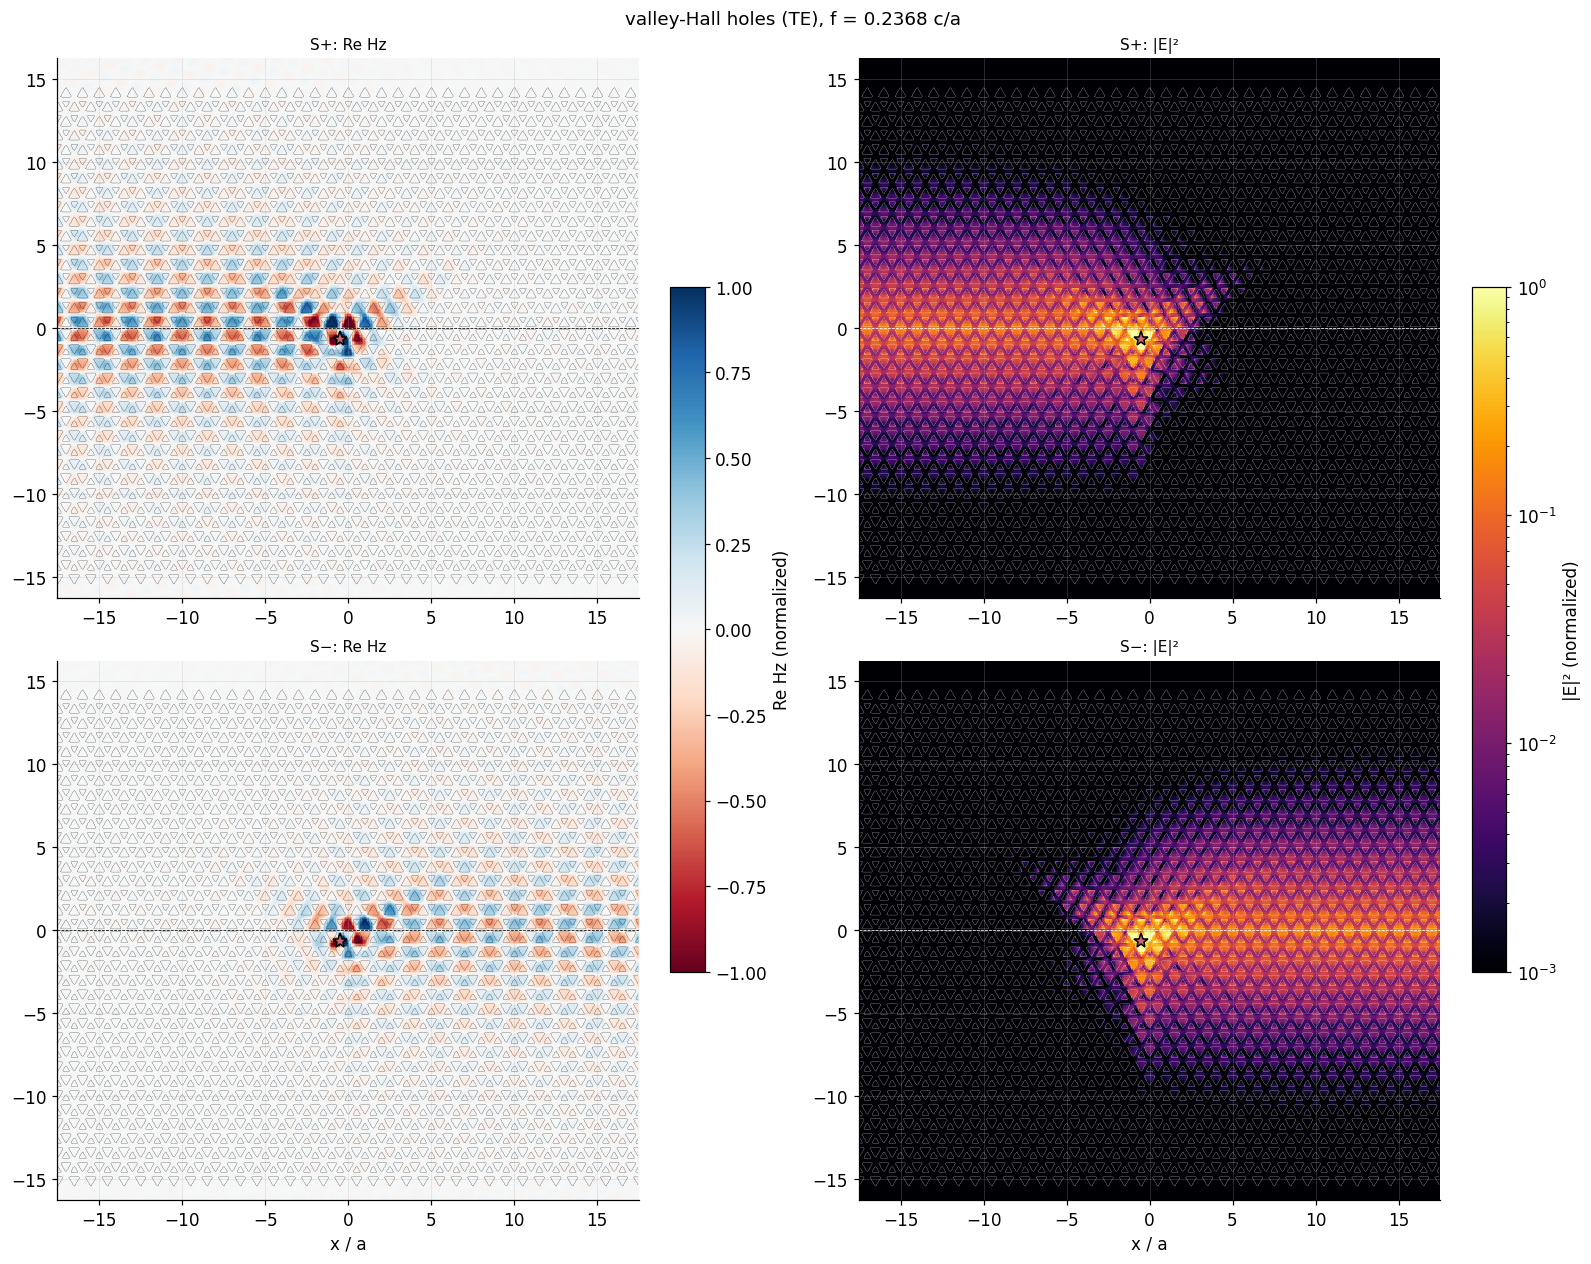

In [6]:
field_figure("valley_te")

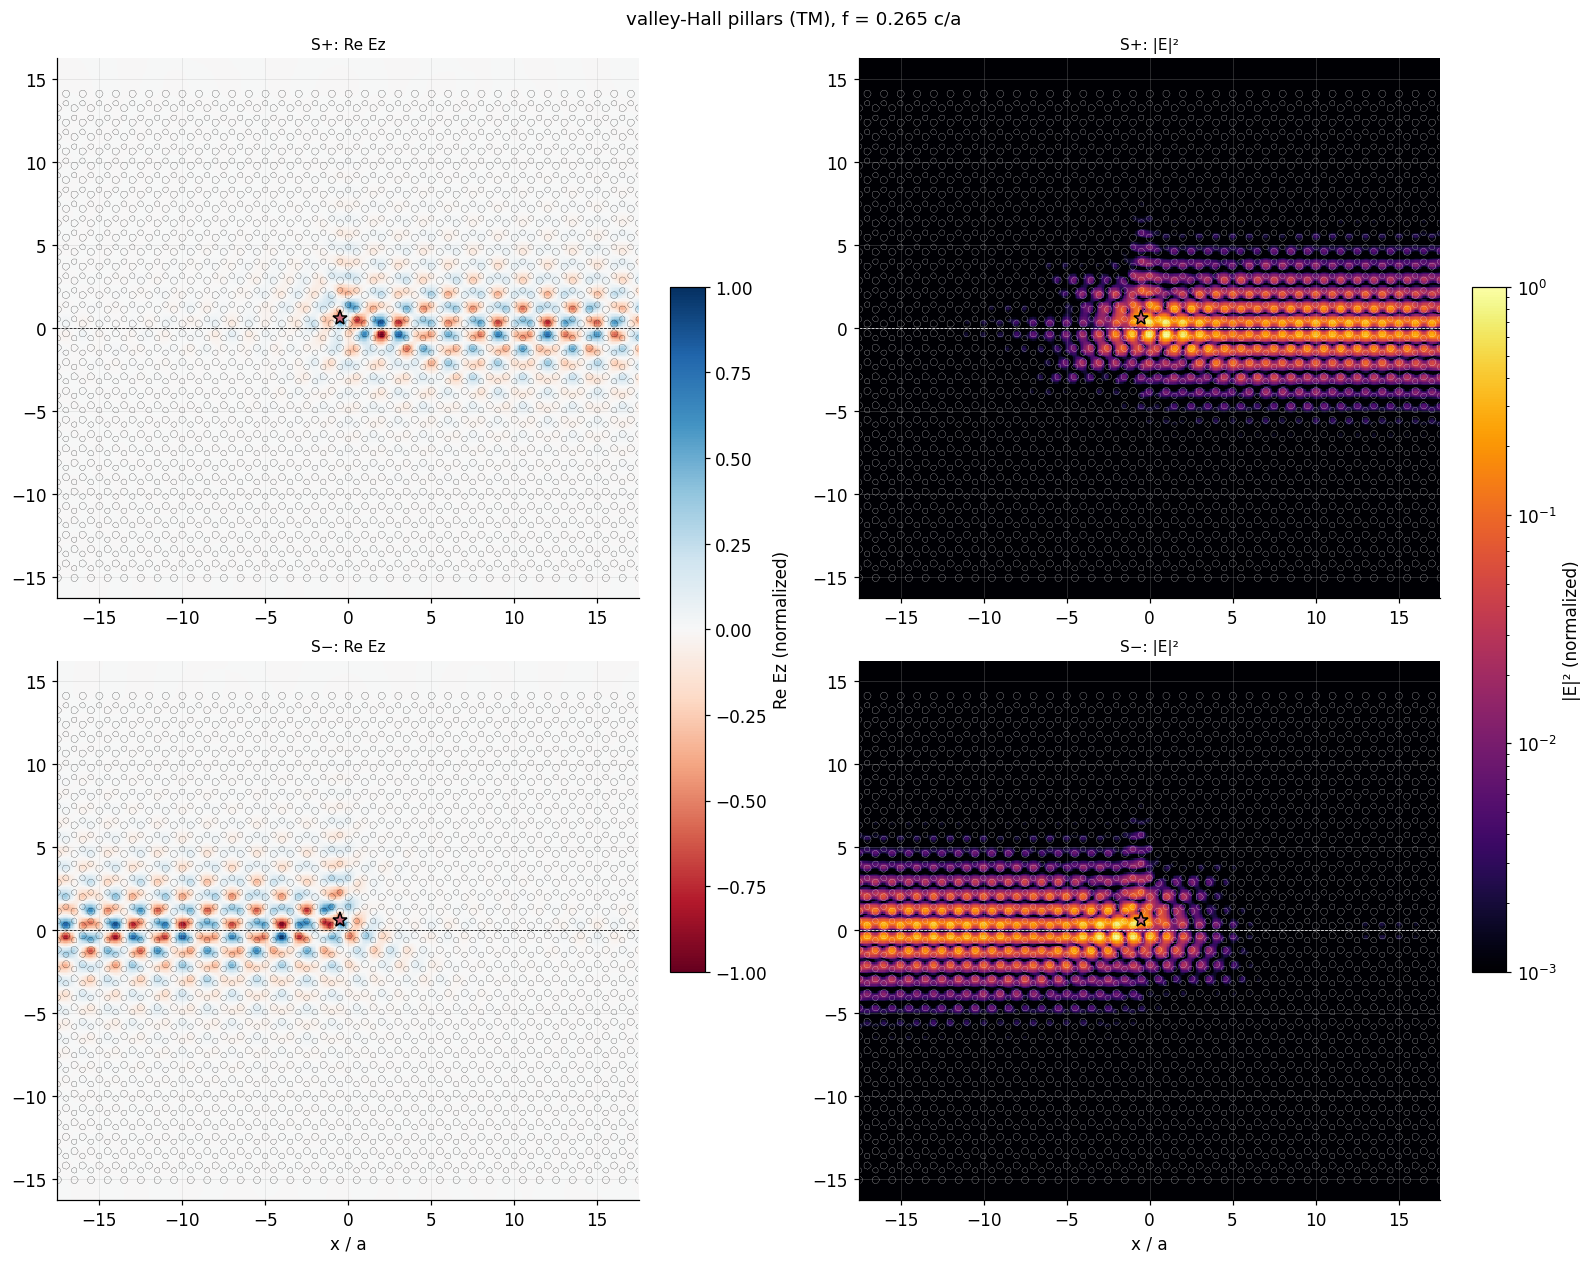

In [7]:
field_figure("valley_tm")

## 4. Directionality

Power through a closed box around the source (vertical lines 8 a0 / 14 a from the source
along the wall, horizontal lines just inside the PML across it), evaluated at full
resolution. η = (P_left − P_right)/(P_left + P_right). The sample is mirror-symmetric about
the vertical line through the source, and that mirror swaps S+ and S− as well as left and
right; the ratio of S+'s dominant channel to the mirrored channel of S− checks the
numerics.

In [8]:
# Power split for every wall and handedness; mirror check: dominant channel of S+ over the
# mirrored channel of S- (P_left(S+) / P_right(S-) when S+ goes left).
print(f"{'wall':>26} {'src':>4} {'P_left':>8} {'P_right':>8} {'through bulk':>13} {'η':>8} {'mirror check':>13}")
for kind in tp.KINDS:
    o = {s: load(kind, s) for s in (+1, -1)}
    a, b = ("left", "right") if o[+1]["P_left"] > o[+1]["P_right"] else ("right", "left")
    for s in (+1, -1):
        P = {k: float(o[s][f"P_{k}"]) for k in ("left", "right", "top", "bottom")}
        tot = sum(P.values())
        eta = (P["left"] - P["right"]) / (P["left"] + P["right"])
        chk = f"{float(o[+1][f'P_{a}'] / o[-1][f'P_{b}']):.4f}" if s > 0 else ""
        print(f"{TITLE[kind]:>26} {'S+' if s > 0 else 'S−':>4} {P['left'] / tot:>8.3f} {P['right'] / tot:>8.3f} "
              f"{(P['top'] + P['bottom']) / tot:>13.3f} {eta:>+8.3f} {chk:>13}")

                      wall  src   P_left  P_right  through bulk        η  mirror check
    spin-Hall pillars (TM)   S+    0.003    0.997         0.000   -0.994        1.0000
    spin-Hall pillars (TM)   S−    0.997    0.003         0.000   +0.994              


      spin-Hall holes (TE)   S+    0.987    0.005         0.008   +0.990        1.0000
      spin-Hall holes (TE)   S−    0.005    0.987         0.008   -0.990              
    valley-Hall holes (TE)   S+    0.987    0.001         0.012   +0.997        1.0018
    valley-Hall holes (TE)   S−    0.002    0.986         0.012   -0.996              
  valley-Hall pillars (TM)   S+    0.001    0.999         0.000   -0.998        0.9951
  valley-Hall pillars (TM)   S−    0.998    0.002         0.000   +0.996              


## 5. A source at a twofold-rotation centre (valley-Hall holes)

The same S± dipole placed at the centre of the hexagon of holes on the bearded wall, a
point about which the wall is C2-symmetric.

In [9]:
# Valley-Hall holes, source at the hexagon centre on the wall.
for s in (+1, -1):
    o = load("valley_te", s, "hexcentre")
    P = {k: float(o[f"P_{k}"]) for k in ("left", "right", "top", "bottom")}
    tot = sum(P.values())
    print(f"hexagon centre, {'S+' if s > 0 else 'S−'}: P_left {P['left'] / tot:.3f}, P_right {P['right'] / tot:.3f}, "
          f"η = {(P['left'] - P['right']) / (P['left'] + P['right']):+.4f}")

hexagon centre, S+: P_left 0.494, P_right 0.494, η = +0.0001
hexagon centre, S−: P_left 0.494, P_right 0.494, η = -0.0001


## 6. Summary

- **One-way excitation on all four walls.** η = 0.998 (valley-Hall pillars), 0.997
  (valley-Hall holes), 0.994 (spin-Hall pillars) and 0.990 (spin-Hall holes); the mirror
  check holds to 0.5 %. S+ goes left on the two hole walls and right on the two pillar
  walls: the sign of C at the source point, not the wall alone, fixes the direction.
- **The source point sets η through both C and S0.** The edge mode is circularly polarized
  (|C| ≈ 1) at many points of the unit cell; among them, the points where the source also
  couples strongly give the highest η, because less of the emitted power goes into the bulk
  crystals, which carry it both ways. At most 1.2 % of the power leaves through the bulk.
- **A drive near a gap edge needs a large, finely resolved sample.** The spin-Hall hole wall
  is driven 0.004 c/a0 above its lower gap edge, so the bulk fields decay slowly away from
  the wall: 10 rows per side lose 15 % through the bulk, 20 rows 0.8 %. Its directionality
  converges only at 64/a0 (η = 0.83 at 32/a0), whereas the other walls are converged at
  24–32 grid points per lattice constant.
- **No directionality at a C2 centre.** At the hexagon centre on the valley-Hall hole wall
  the same sources split the power exactly evenly (η = 10⁻⁴), as C = 0 there.
- The valley-Hall walls guide their edge states near K with gaps of 6.8 % (holes) and 8.7 %
  (pillars), against 3–4 % for the spin-Hall gaps, and confine the light more tightly to the
  wall at comparable sample size.